<a href="https://colab.research.google.com/github/Jood58/01-ImageProcessing-lab1/blob/main/Assigment_1_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Imam Abdulrahman Bin Faisal University
## ARTI 502 – Deep Learning
### Assignment 1: Training and Testing Neural Network with MNIST Dataset Using PyTorch

**Instructor:** Dr. Moatasem Alsmadi

**Group Number:** 4

**Group Members:**
1. Renad Salem Alqahtani – 2230004724
2. Jana Omar Alghamdi – 2230002367
3. Jood Yasser Alarfaj – 2230002692
4. [Student Name] – [Academic ID]
5. [Student Name] – [Academic ID]
6. [Student Name] – [Academic ID]


##Task 1: Install PyTorch

In [ ]:
%pip install torch

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("PyTorch installed successfully!")

PyTorch version: 2.11.0+cpu
PyTorch installed successfully!


##Task 2: Download and Load the Dataset


In [ ]:
import torch
from torchvision import datasets, transforms

# Convert images to PyTorch tensors
transform = transforms.ToTensor()

# Download and load the MNIST dataset
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("MNIST dataset loaded successfully!")
print("Training dataset size:", len(train_dataset))
print("Testing dataset size:", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 62.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.83MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.6MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.83MB/s]

MNIST dataset loaded successfully!
Training dataset size: 60000
Testing dataset size: 10000


##Task 3: Inspect the Dataset

Batch of images shape: torch.Size([64, 1, 28, 28])
Batch of labels shape: torch.Size([64])


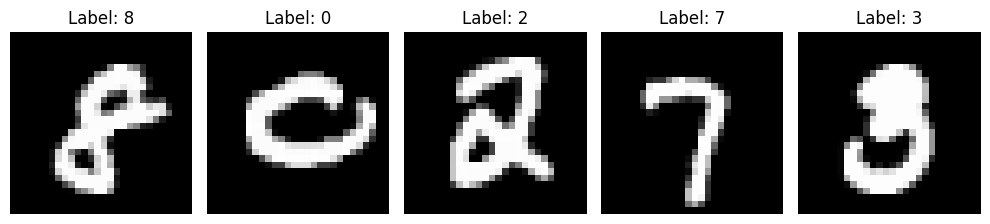

In [ ]:
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

# Create a DataLoader to easily iterate through the dataset
train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)

# Get one batch of training images and labels
data_iter = iter(train_loader)
images, labels = next(data_iter)

print("Batch of images shape:", images.shape)
print("Batch of labels shape:", labels.shape)

# Visualize some samples from the batch
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for i in range(5):
    # squeeze() removes the single-channel dimension
    axes[i].imshow(images[i].squeeze(), cmap='gray')
    axes[i].set_title(f"Label: {labels[i].item()}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

##Task 4: Creating A Simple Network

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Define a simple feedforward neural network
class SimpleNeuralNet(nn.Module):
    def __init__(self, input_size=784, hidden_size=128, num_classes=10):
        super(SimpleNeuralNet, self).__init__()
        # First fully connected layer
        self.fc1 = nn.Linear(input_size, hidden_size)
        # Second fully connected layer
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # Flatten the image from (N, C, H, W) to (N, I) using torch.flatten
        # start_dim=1 ensures we keep the batch dimension intact
        x = torch.flatten(x, start_dim=1)
        # Apply activation function to the hidden layer
        x = F.relu(self.fc1(x))
        # Output layer
        x = self.fc2(x)
        return x

# Instantiate the model and print its architecture
model = SimpleNeuralNet()
print(model)

SimpleNeuralNet(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


##Task 5: Training Function

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

def train_network(net, train_loader, epochs=5, lr=0.01, momentum=0.9):
    """
    Trains the given neural network using cross-entropy loss and stochastic gradient descent.

    Parameters:
    - net: The PyTorch neural network model to train.
    - train_loader: DataLoader containing the training dataset.
    - epochs: Number of passes over the training dataset.
    - lr: Learning rate for the SGD optimizer.
    - momentum: Momentum for the SGD optimizer.
    """
    # 1. Define the loss function (Cross-Entropy Loss)
    criterion = nn.CrossEntropyLoss()

    # 2. Define the optimizer (Stochastic Gradient Descent with lr and momentum)
    optimizer = optim.SGD(net.parameters(), lr=lr, momentum=momentum)

    # Put the network in training mode
    net.train()

    print(f"Starting training for {epochs} epochs (Learning Rate: {lr}, Momentum: {momentum})...")

    for epoch in range(epochs):
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for batch_idx, (images, labels) in enumerate(train_loader):
            # Zero the parameter gradients to prevent accumulation from previous batches
            optimizer.zero_grad()

            # Forward pass: compute predicted outputs by passing inputs to the model
            outputs = net(images)

            # Calculate the loss
            loss = criterion(outputs, labels)

            # Backward pass: compute gradient of the loss with respect to model parameters
            loss.backward()

            # Perform a single optimization step (parameter update)
            optimizer.step()

            # Track training metrics
            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

        epoch_loss = running_loss / total_samples
        epoch_acc = (correct_predictions / total_samples) * 100

        print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f} - Accuracy: {epoch_acc:.2f}%")

    print("Training completed successfully!")


##Task 6: Training Network

##Task 7: Testing Network

##Task 8: Tuning the parameters and model archirecture